Apply feature importance analysis using Decision Trees by manually constructing a decision tree algorithm from scratch, computing Gini impurity or entropy values, and ranking features without using scikit-learn.

In [1]:
import pandas as pd
import math

# Load dataset
df = pd.read_csv("heart_disease_with_risk_factor.csv")

# Numerical features
feature_columns = [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak"
]

target_column = "target"

print("Dataset loaded successfully!")
print(df.head())

Dataset loaded successfully!
   patient_id  age     sex                cp  trestbps  chol    fbs restecg  \
0           1   69    Male    Typical Angina       188   266  False  Normal   
1           2   56    Male    Typical Angina       105   237  False     LVH   
2           3   57  Female    Typical Angina       191   538  False     LVH   
3           4   34  Female    Typical Angina       139   559   True     LVH   
4           5   34  Female  Non-anginal Pain       167   224  False  Normal   

   thalach exang  oldpeak        slope     ca               thal  target  \
0      106    No      4.2  Downsloping   Zero  Reversible Defect       1   
1       77    No      4.4  Downsloping  Three             Normal       0   
2      179   Yes      1.7    Upsloping    Two             Normal       1   
3      138    No      4.5  Downsloping   Zero       Fixed Defect       0   
4      129   Yes      6.1    Upsloping   Zero       Fixed Defect       1   

   chol_percentile  thalach_percentile 

In [2]:
# Calculate Gini impurity
def gini_impurity(labels):

    if len(labels) == 0:
        return 0

    class_counts = {}

    for label in labels:

        if label not in class_counts:
            class_counts[label] = 0

        class_counts[label] += 1

    impurity = 1

    total = len(labels)

    for label in class_counts:

        probability = (
            class_counts[label] / total
        )

        impurity -= (
            probability ** 2
        )

    return impurity

In [3]:
# Find the best split for one feature
def find_best_split(data, feature, target):

    values = []

    for value in data[feature]:

        if pd.notna(value):
            values.append(float(value))

    if len(values) < 2:
        return None

    # Sort values manually
    for i in range(len(values)):

        for j in range(i + 1, len(values)):

            if values[i] > values[j]:

                values[i], values[j] = (
                    values[j],
                    values[i]
                )

    # Create candidate thresholds
    thresholds = []

    for i in range(len(values) - 1):

        if values[i] != values[i + 1]:

            threshold = (
                values[i]
                +
                values[i + 1]
            ) / 2

            thresholds.append(
                threshold
            )

    best_threshold = None
    best_gini = float("inf")
    best_gain = 0

    parent_labels = []

    for i in range(len(data)):

        feature_value = data[feature].iloc[i]
        target_value = data[target].iloc[i]

        if (
            pd.notna(feature_value)
            and
            pd.notna(target_value)
        ):

            parent_labels.append(
                target_value
            )

    parent_gini = gini_impurity(
        parent_labels
    )

    total = len(parent_labels)

    # Test every threshold
    for threshold in thresholds:

        left_labels = []
        right_labels = []

        for i in range(len(data)):

            feature_value = data[feature].iloc[i]
            target_value = data[target].iloc[i]

            if (
                pd.notna(feature_value)
                and
                pd.notna(target_value)
            ):

                if float(feature_value) <= threshold:

                    left_labels.append(
                        target_value
                    )

                else:

                    right_labels.append(
                        target_value
                    )

        if (
            len(left_labels) == 0
            or
            len(right_labels) == 0
        ):
            continue

        left_gini = gini_impurity(
            left_labels
        )

        right_gini = gini_impurity(
            right_labels
        )

        weighted_gini = (
            (
                len(left_labels)
                / total
            )
            * left_gini
            +
            (
                len(right_labels)
                / total
            )
            * right_gini
        )

        gain = (
            parent_gini
            -
            weighted_gini
        )

        if weighted_gini < best_gini:

            best_gini = weighted_gini
            best_threshold = threshold
            best_gain = gain

    if best_threshold is None:
        return None

    return {
        "threshold": best_threshold,
        "gini": best_gini,
        "gain": best_gain,
        "parent_gini": parent_gini
    }

In [4]:
# Build decision tree recursively
def build_tree(
    data,
    features,
    target,
    depth=0,
    max_depth=3,
    min_samples=5,
    importance=None
):

    if importance is None:

        importance = {}

        for feature in features:
            importance[feature] = 0


    # Get target labels
    labels = []

    for value in data[target]:

        if pd.notna(value):
            labels.append(value)


    # Stop if node is pure
    unique_labels = []

    for label in labels:

        if label not in unique_labels:
            unique_labels.append(label)


    if len(unique_labels) <= 1:

        return {
            "type": "leaf",
            "prediction": labels[0]
        }


    # Stop conditions
    if (
        depth >= max_depth
        or
        len(data) < min_samples
    ):

        class_counts = {}

        for label in labels:

            if label not in class_counts:
                class_counts[label] = 0

            class_counts[label] += 1

        majority_class = None
        highest_count = -1

        for label in class_counts:

            if class_counts[label] > highest_count:

                highest_count = (
                    class_counts[label]
                )

                majority_class = label


        return {
            "type": "leaf",
            "prediction": majority_class
        }


    # Find best feature and split
    best_feature = None
    best_split = None
    best_gain = 0

    for feature in features:

        split = find_best_split(
            data,
            feature,
            target
        )

        if split is not None:

            if split["gain"] > best_gain:

                best_gain = split["gain"]
                best_feature = feature
                best_split = split


    # Stop if no useful split exists
    if best_feature is None:

        class_counts = {}

        for label in labels:

            if label not in class_counts:
                class_counts[label] = 0

            class_counts[label] += 1

        majority_class = None
        highest_count = -1

        for label in class_counts:

            if class_counts[label] > highest_count:

                highest_count = (
                    class_counts[label]
                )

                majority_class = label

        return {
            "type": "leaf",
            "prediction": majority_class
        }


    # Store impurity reduction
    importance[best_feature] += (
        best_gain * len(data)
    )


    # Create left and right datasets
    left_indices = []
    right_indices = []

    threshold = best_split[
        "threshold"
    ]

    for i in range(len(data)):

        value = data[best_feature].iloc[i]

        if pd.notna(value):

            if float(value) <= threshold:

                left_indices.append(i)

            else:

                right_indices.append(i)


    left_data = data.iloc[
        left_indices
    ].reset_index(drop=True)

    right_data = data.iloc[
        right_indices
    ].reset_index(drop=True)


    # Recursively build branches
    left_tree = build_tree(
        left_data,
        features,
        target,
        depth + 1,
        max_depth,
        min_samples,
        importance
    )

    right_tree = build_tree(
        right_data,
        features,
        target,
        depth + 1,
        max_depth,
        min_samples,
        importance
    )


    return {
        "type": "node",
        "feature": best_feature,
        "threshold": threshold,
        "gini": best_split["gini"],
        "gain": best_gain,
        "left": left_tree,
        "right": right_tree
    }

In [5]:
# Remove rows with missing values
tree_data = df[
    feature_columns + [target_column]
].copy()

tree_data = tree_data.dropna()

# Create importance dictionary
feature_importance = {}

for feature in feature_columns:
    feature_importance[feature] = 0

# Build tree
decision_tree = build_tree(
    tree_data,
    feature_columns,
    target_column,
    max_depth=3,
    min_samples=5,
    importance=feature_importance
)

print("Decision Tree created successfully!")

Decision Tree created successfully!


In [6]:
# Display tree structure
def print_tree(node, spacing=""):

    if node["type"] == "leaf":

        print(
            spacing
            + "Leaf -> Prediction: "
            + str(node["prediction"])
        )

        return


    print(
        spacing
        + "Feature: "
        + node["feature"]
    )

    print(
        spacing
        + "Threshold: "
        + str(round(
            node["threshold"],
            3
        ))
    )

    print(
        spacing
        + "Gini Gain: "
        + str(round(
            node["gain"],
            4
        ))
    )

    print(
        spacing
        + "Left:"
    )

    print_tree(
        node["left"],
        spacing + "    "
    )

    print(
        spacing
        + "Right:"
    )

    print_tree(
        node["right"],
        spacing + "    "
    )


print("\nMANUAL DECISION TREE")
print("=" * 60)

print_tree(decision_tree)


MANUAL DECISION TREE
Feature: age
Threshold: 35.0
Gini Gain: 0.0894
Left:
    Feature: trestbps
    Threshold: 153.0
    Gini Gain: 0.2133
    Left:
        Leaf -> Prediction: 0
    Right:
        Feature: oldpeak
        Threshold: 1.55
        Gini Gain: 0.4444
        Left:
            Leaf -> Prediction: 0
        Right:
            Leaf -> Prediction: 1
Right:
    Feature: chol
    Threshold: 238.5
    Gini Gain: 0.0399
    Left:
        Feature: thalach
        Threshold: 139.0
        Gini Gain: 0.1541
        Left:
            Leaf -> Prediction: 0
        Right:
            Leaf -> Prediction: 1
    Right:
        Feature: age
        Threshold: 49.5
        Gini Gain: 0.0086
        Left:
            Leaf -> Prediction: 1
        Right:
            Leaf -> Prediction: 1


In [7]:
# Calculate total importance
total_importance = 0

for feature in feature_importance:

    total_importance += (
        feature_importance[feature]
    )


# Normalize importance
importance_results = []

for feature in feature_columns:

    if total_importance > 0:

        importance = (
            feature_importance[feature]
            /
            total_importance
        )

    else:

        importance = 0

    importance_results.append({
        "Feature": feature,
        "Importance": round(
            importance,
            4
        )
    })


# Create ranking table
importance_df = pd.DataFrame(
    importance_results
)

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

importance_df = importance_df.reset_index(
    drop=True
)

importance_df["Rank"] = (
    importance_df.index + 1
)

importance_df = importance_df[
    [
        "Rank",
        "Feature",
        "Importance"
    ]
]


print("\nFEATURE IMPORTANCE RANKING")
print("=" * 60)

print(
    importance_df.to_string(
        index=False
    )
)


FEATURE IMPORTANCE RANKING
 Rank  Feature  Importance
    1      age      0.4191
    2  thalach      0.1707
    3     chol      0.1503
    4 trestbps      0.1418
    5  oldpeak      0.1181


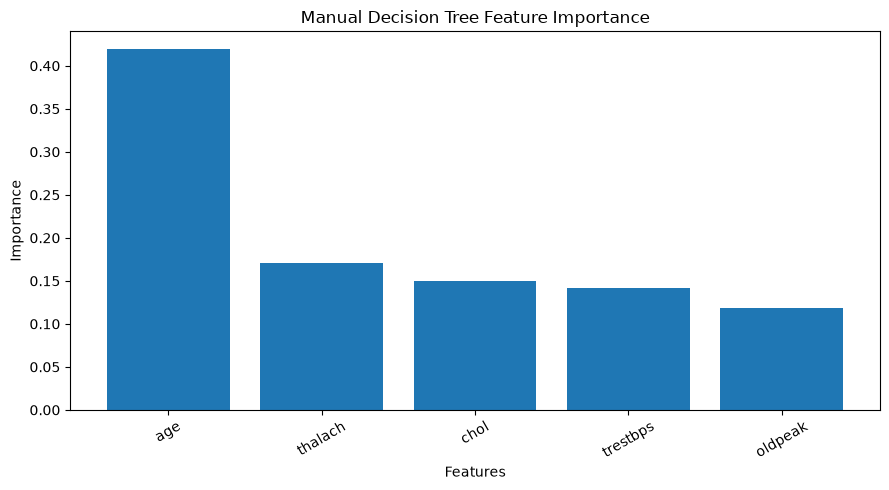

In [8]:
import matplotlib.pyplot as plt

# Create feature importance chart
plt.figure(figsize=(9, 5))

plt.bar(
    importance_df["Feature"],
    importance_df["Importance"]
)

plt.xlabel("Features")
plt.ylabel("Importance")
plt.title(
    "Manual Decision Tree Feature Importance"
)

plt.xticks(
    rotation=30
)

plt.tight_layout()

plt.show()